## 1. Load and inspect the CSV

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Google Colab upload flow
try:
    from google.colab import files
    uploaded = files.upload()
    csv_name = next((name for name in uploaded if name.lower().endswith(".csv")), None)
    if csv_name is None:
        raise FileNotFoundError("Please upload AirQualityUCI.csv.")
    # UCI data is often semicolon-delimited and decimal-comma formatted.
    try:
        raw = pd.read_csv(csv_name, sep=";", decimal=",", encoding="utf-8")
        if raw.shape[1] < 5:
            raw = pd.read_csv(csv_name, sep=None, engine="python", decimal=",", encoding="utf-8")
    except Exception:
        raw = pd.read_csv(csv_name, sep=None, engine="python", decimal=",", encoding="latin1")
except ImportError:
    # Local Jupyter fallback
    try:
        raw = pd.read_csv("AirQualityUCI.csv", sep=";", decimal=",", encoding="utf-8")
        if raw.shape[1] < 5:
            raw = pd.read_csv("AirQualityUCI.csv", sep=None, engine="python", decimal=",", encoding="utf-8")
    except Exception:
        raw = pd.read_csv("AirQualityUCI.csv", sep=None, engine="python", decimal=",", encoding="latin1")

raw.columns = [str(c).strip().replace("\ufeff", "") for c in raw.columns]
print("Raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())


Saving AirQualityUCI.csv to AirQualityUCI.csv
Raw shape: (9471, 17)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Unnamed: 15', 'Unnamed: 16']


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


## 2. Parse timestamps and clean the selected variables

In [2]:

# Normalize column names for robust lookup.
column_lookup = {c.strip().lower(): c for c in raw.columns}
date_col = next((column_lookup[k] for k in column_lookup if k == "date"), None)
time_col = next((column_lookup[k] for k in column_lookup if k == "time"), None)
co_col = next((column_lookup[k] for k in column_lookup if "co(gt)" in k), None)
nox_col = next((column_lookup[k] for k in column_lookup if "nox(gt)" in k), None)

if not all([date_col, time_col, co_col, nox_col]):
    raise ValueError("Could not locate Date, Time, CO(GT), and NOx(GT). Inspect the printed column names and adjust the column names.")

df = raw[[date_col, time_col, co_col, nox_col]].copy()
df.columns = ["Date", "Time", "CO", "NOx"]

# UCI dates commonly use dd/mm/yyyy; parse explicitly.
df["timestamp"] = pd.to_datetime(
    df["Date"].astype(str).str.strip() + " " + df["Time"].astype(str).str.strip(),
    format="%d/%m/%Y %H.%M.%S",
    errors="coerce"
)
# Fallback for variants such as HH:MM:SS
bad = df["timestamp"].isna()
if bad.any():
    fallback = pd.to_datetime(
        df.loc[bad, "Date"].astype(str).str.strip() + " " + df.loc[bad, "Time"].astype(str).str.strip(),
        dayfirst=True, errors="coerce"
    )
    df.loc[bad, "timestamp"] = fallback

for c in ["CO", "NOx"]:
    # Convert string values with decimal commas as well as already parsed numeric values.
    df[c] = pd.to_numeric(df[c].astype(str).str.strip().str.replace(",", ".", regex=False), errors="coerce")
    df[c] = df[c].replace(-200, np.nan)

df = df.dropna(subset=["timestamp"]).sort_values("timestamp")
df = df.drop_duplicates(subset="timestamp").set_index("timestamp")[["CO", "NOx"]]

print("Date range:", df.index.min(), "to", df.index.max())
print("Rows after timestamp parsing:", len(df))
print("Missing values after replacing -200:")
display(df.isna().sum().to_frame("missing_count"))
display(df.head())


Date range: 2004-03-10 18:00:00 to 2005-04-04 14:00:00
Rows after timestamp parsing: 9357
Missing values after replacing -200:


,missing_count
CO,1683
NOx,1639


,CO,NOx
timestamp,,
2004-03-10 18:00:00,2.6,166.0
2004-03-10 19:00:00,2.0,103.0
2004-03-10 20:00:00,2.2,131.0
2004-03-10 21:00:00,2.2,172.0
2004-03-10 22:00:00,1.6,131.0


## 3. Resample to daily means and prepare modelling data



Daily rows available: 361
Remaining missing values: {'CO': 0, 'NOx': 0}


,CO,NOx
timestamp,,
2004-03-11,2.239130,144.391304
2004-03-12,2.804545,173.727273
2004-03-13,2.695652,184.434783
2004-03-14,2.469565,146.608696
2004-03-15,3.504348,215.130435


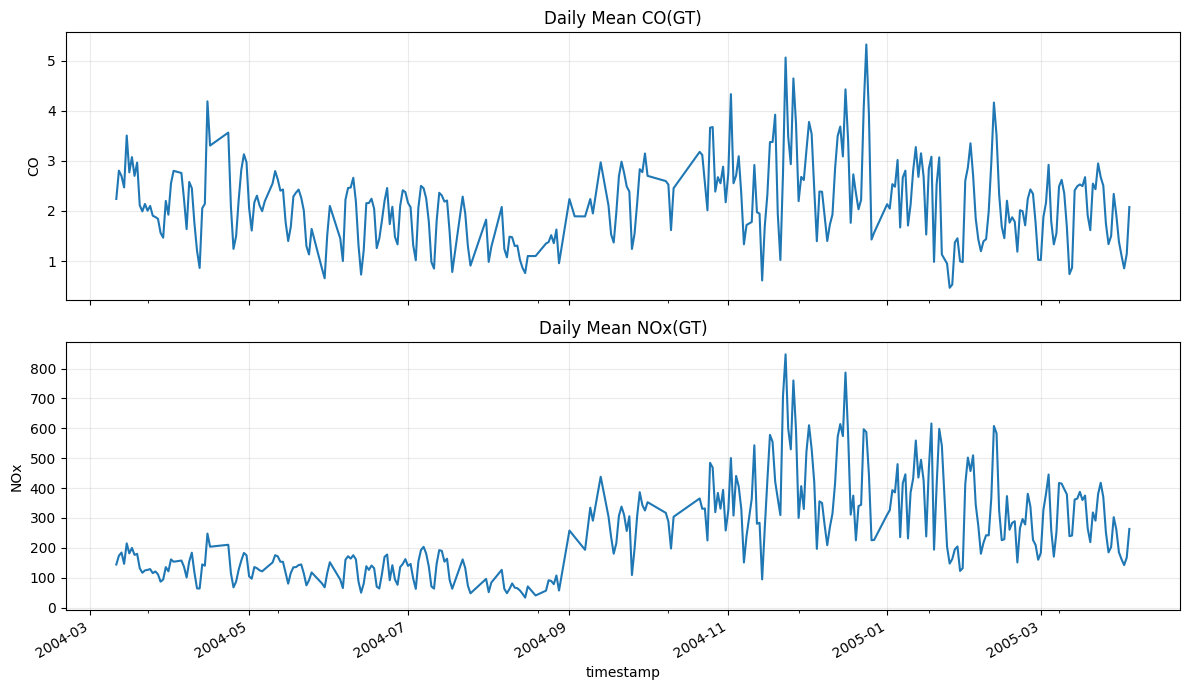

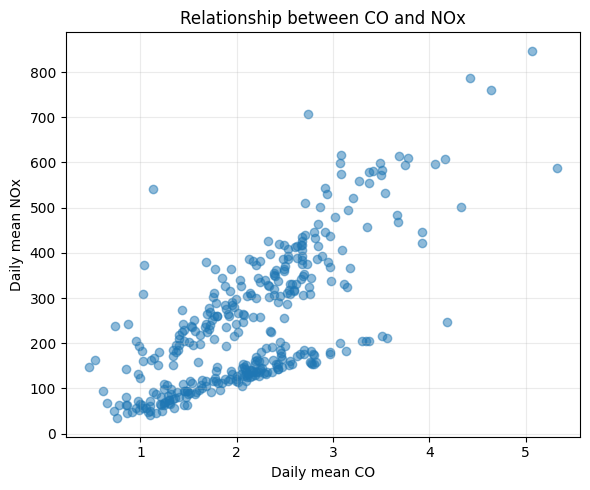

In [3]:
daily = df.resample("D").mean()
hour_counts = df["CO"].resample("D").count()
daily.loc[hour_counts < 12, :] = np.nan

# Time interpolation fills short gaps, with a limited gap length.
daily = daily.interpolate(method="time", limit=2, limit_area="inside").dropna()

print("Daily rows available:", len(daily))
print("Remaining missing values:", daily.isna().sum().to_dict())
display(daily.head())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
daily["CO"].plot(ax=axes[0], title="Daily Mean CO(GT)")
axes[0].set_ylabel("CO")
daily["NOx"].plot(ax=axes[1], title="Daily Mean NOx(GT)")
axes[1].set_ylabel("NOx")
for ax in axes:
    ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 5))
plt.scatter(daily["CO"], daily["NOx"], alpha=0.5)
plt.xlabel("Daily mean CO")
plt.ylabel("Daily mean NOx")
plt.title("Relationship between CO and NOx")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


## 4. Check stationarity

In [4]:
def stationarity_report(series, label):
    series = pd.Series(series).dropna()
    print(f"\n{label}")
    adf_result = adfuller(series, autolag="AIC")
    print(f"ADF statistic: {adf_result[0]:.4f}; p-value: {adf_result[1]:.4f}")
    try:
        kpss_result = kpss(series, regression="c", nlags="auto")
        print(f"KPSS statistic: {kpss_result[0]:.4f}; p-value: {kpss_result[1]:.4f}")
    except Exception as e:
        print("KPSS unavailable:", e)
    print("ADF null: unit root/non-stationary. KPSS null: stationary.")

for col in ["CO", "NOx"]:
    stationarity_report(daily[col], f"{col} level series")
    stationarity_report(daily[col].diff().dropna(), f"{col} first difference")




CO level series
ADF statistic: -4.2079; p-value: 0.0006
KPSS statistic: 0.3165; p-value: 0.1000
ADF null: unit root/non-stationary. KPSS null: stationary.

CO first difference
ADF statistic: -8.7028; p-value: 0.0000
KPSS statistic: 0.0642; p-value: 0.1000
ADF null: unit root/non-stationary. KPSS null: stationary.

NOx level series
ADF statistic: -1.7988; p-value: 0.3811
KPSS statistic: 2.0191; p-value: 0.0100
ADF null: unit root/non-stationary. KPSS null: stationary.

NOx first difference
ADF statistic: -6.7248; p-value: 0.0000
KPSS statistic: 0.0783; p-value: 0.1000
ADF null: unit root/non-stationary. KPSS null: stationary.


/tmp/ipykernel_611/3570254203.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_611/3570254203.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_611/3570254203.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression="c", nlags="auto")
/tmp/ipykernel_611/3570254203.py:7: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result =

## 5. Chronological train/test split and scaling



In [5]:
test_size = max(14, int(round(len(daily) * 0.2)))
if len(daily) - test_size < 50:
    raise ValueError("Not enough daily observations remain for a reliable train/test split.")

train_raw = daily.iloc[:-test_size].copy()
test_raw = daily.iloc[-test_size:].copy()

mean_train = train_raw.mean()
std_train = train_raw.std().replace(0, 1)

train = (train_raw - mean_train) / std_train
test = (test_raw - mean_train) / std_train

print("Train rows:", len(train), "| Test rows:", len(test))
print("Test period:", test.index.min().date(), "to", test.index.max().date())


Train rows: 289 | Test rows: 72
Test period: 2005-01-23 to 2005-04-04


## 6. Fit VAR model and select lag order

In [6]:
# VAR requires stationary input. We use first differences of the standardized training data.
# Forecasts of differences are accumulated to reconstruct levels.
train_diff = train.diff().dropna()

var_model = VAR(train_diff)
maxlags = min(10, max(1, len(train_diff) // 10))
lag_selection = var_model.select_order(maxlags=maxlags)
print(lag_selection.summary())

# Prefer AIC-selected lag; fallback to lag 1 if selection is unavailable/invalid.
selected_lag = lag_selection.selected_orders.get("aic", None)
if selected_lag is None or selected_lag < 1:
    selected_lag = 1
selected_lag = min(int(selected_lag), maxlags)
print("Selected VAR lag by AIC:", selected_lag)

var_fit = var_model.fit(selected_lag)
print(var_fit.summary())


 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -2.657      -2.631     0.07016      -2.646
1       -2.693      -2.615     0.06765      -2.662
2       -2.823      -2.693     0.05942      -2.771
3       -2.907      -2.724     0.05463      -2.834
4       -2.947      -2.712     0.05249      -2.853
5       -3.072      -2.785     0.04635      -2.956
6       -3.125     -2.785*     0.04396     -2.989*
7       -3.105      -2.713     0.04485      -2.948
8       -3.133      -2.689     0.04360      -2.955
9      -3.134*      -2.638    0.04358*      -2.935
10      -3.129      -2.581     0.04379      -2.909
--------------------------------------------------
Selected VAR lag by AIC: 9
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 19, Oct, 2026
Time:                     05:29:26
---------------------------------

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [7]:
# VAR forecast in differences, then integrate to level scale.
h = len(test)
var_diff_forecast = var_fit.forecast(train_diff.values[-selected_lag:], steps=h)
var_diff_forecast = pd.DataFrame(var_diff_forecast, index=test.index, columns=train.columns)

# Reconstruct standardized levels from last observed training level.
last_level = train.iloc[-1].values
var_level_scaled = pd.DataFrame(
    last_level + np.cumsum(var_diff_forecast.values, axis=0),
    index=test.index, columns=train.columns
)
var_forecast = var_level_scaled * std_train + mean_train


## 7. Fit VARMA-style model using VARMAX

`statsmodels` provides VARMAX, which supports vector autoregressive and moving-average terms. We fit a small VARMA(1,1) candidate on the standardized differenced series. If it does not converge, the notebook will report that fact and try a simpler VARMA(1,0) specification. Model performance should only be compared when the fit is numerically stable.

In [9]:
varma_fit = None
varma_order_used = None

# Ensure the training data has an explicit frequency set for statsmodels forecasting
train_diff_freq = train_diff.asfreq("D")

for order in [(1, 1), (1, 0)]:
    try:
        candidate = VARMAX(
            train_diff_freq,
            order=order,
            trend="c",
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        fitted = candidate.fit(disp=False, maxiter=300)
        converged = getattr(fitted, "mle_retvals", {}).get("converged", True)
        print(f"VARMAX{order} converged:", converged)
        if converged:
            varma_fit = fitted
            varma_order_used = order
            break
        else:
            print("Fit did not converge; trying next candidate.")
    except Exception as e:
        print(f"VARMAX{order} failed:", repr(e))

if varma_fit is not None:
    varma_diff_forecast = varma_fit.get_forecast(steps=h).predicted_mean
    varma_diff_forecast.index = test.index
    varma_level_scaled = pd.DataFrame(
        train.iloc[-1].values + np.cumsum(varma_diff_forecast.values, axis=0),
        index=test.index, columns=train.columns
    )
    varma_forecast = varma_level_scaled * std_train + mean_train
    print("Selected stable VARMAX order:", varma_order_used)
else:
    varma_forecast = None
    print("No VARMAX candidate converged. Report this as a modelling challenge; do not invent a VARMA result.")

/tmp/ipykernel_611/3894320918.py:9: EstimationWarning: Estimation of VARMA(p,q) models is not generically robust, due especially to identification issues.
  candidate = VARMAX(


VARMAX(1, 1) converged: True
Selected stable VARMAX order: (1, 1)


## 8. Compare forecasts using MAE and RMSE

In [10]:
def metric_row(model_name, actual_df, forecast_df):
    rows = []
    for col in actual_df.columns:
        actual = actual_df[col].to_numpy(dtype=float)
        pred = forecast_df[col].to_numpy(dtype=float)
        rows.append({
            "Model": model_name,
            "Variable": col,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": np.sqrt(mean_squared_error(actual, pred))
        })
    return rows

comparison_rows = metric_row("VAR", test_raw, var_forecast)
if varma_forecast is not None:
    comparison_rows += metric_row(f"VARMAX{varma_order_used}", test_raw, varma_forecast)

comparison = pd.DataFrame(comparison_rows).sort_values(["Variable", "RMSE"]).reset_index(drop=True)
display(comparison)

# Average RMSE across both variables for a compact overall comparison.
overall = comparison.groupby("Model", as_index=False)["RMSE"].mean().rename(columns={"RMSE": "Mean RMSE across variables"})
display(overall.sort_values("Mean RMSE across variables"))


,Model,Variable,MAE,RMSE
0,VAR,CO,0.720170,0.914213
1,"VARMAX(1, 1)",CO,0.752179,0.924292
2,"VARMAX(1, 1)",NOx,252.442786,271.505951
3,VAR,NOx,284.069317,303.720351


,Model,Mean RMSE across variables
1,"VARMAX(1, 1)",136.215122
0,VAR,152.317282


## 9. Plot actual versus forecast

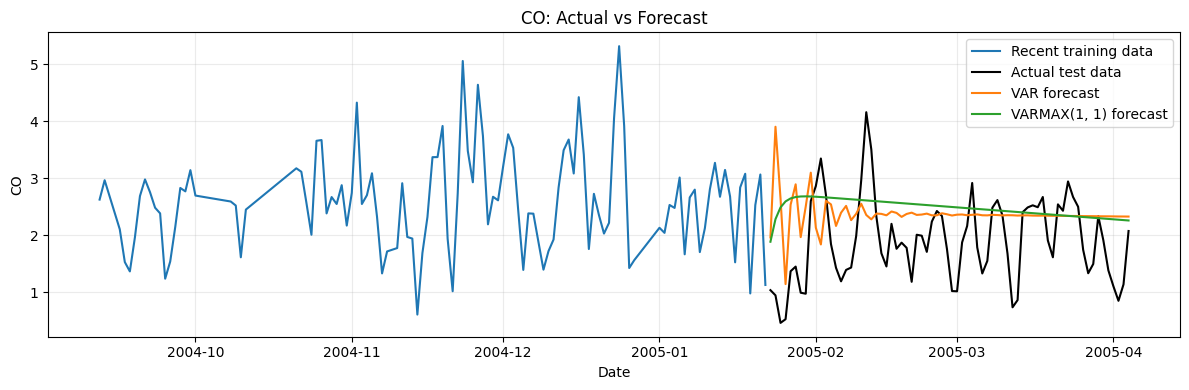

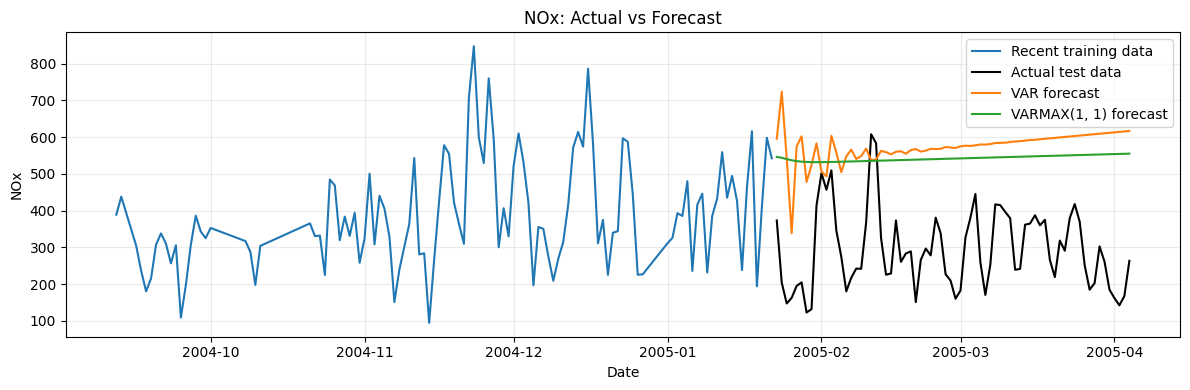

In [11]:
for col in ["CO", "NOx"]:
    plt.figure(figsize=(12, 4))
    plt.plot(train_raw.index[-min(120, len(train_raw)):], train_raw[col].tail(min(120, len(train_raw))),
             label="Recent training data")
    plt.plot(test_raw.index, test_raw[col], label="Actual test data", color="black")
    plt.plot(var_forecast.index, var_forecast[col], label="VAR forecast")
    if varma_forecast is not None:
        plt.plot(varma_forecast.index, varma_forecast[col], label=f"VARMAX{varma_order_used} forecast")
    plt.title(f"{col}: Actual vs Forecast")
    plt.xlabel("Date")
    plt.ylabel(col)
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()


In [12]:
daily.to_csv("air_quality_daily_CO_NOx_cleaned.csv")
comparison.to_csv("multivariate_model_comparison.csv", index=False)
print("Saved: air_quality_daily_CO_NOx_cleaned.csv")
print("Saved: multivariate_model_comparison.csv")


Saved: air_quality_daily_CO_NOx_cleaned.csv
Saved: multivariate_model_comparison.csv
